# Ad Preference Evaluation: Analysis

**Research question:** when the retrieval pipeline assigns an ad to a user query, does an independent
LLM judge agree that it is the most relevant ad, both among ads of the **same category** and against
ads from **other categories**?

### How the data is produced
(`src/ad_evaluation`, `EvaluateAdPreferenceService`)

1. Each query has an **assigned ad**: the top-1 FAISS hit (BGE-M3 embeddings) from `assign_top_ads.py`.
2. The assigned ad is paired with every **candidate ad**:
   - **same-category** run (`run_preference_eval.py`): every other ad in the assigned ad's category
   - **cross-category** run (`run_cross_category_eval.py`): every ad in all *other* categories
3. Each pair is judged **in both orders**: `is_swapped=False` means the assigned ad is `Ad 1`,
   `is_swapped=True` means it is `Ad 2`.
4. The judge (`nvidia/Llama-3.3-70B-Instruct-FP8`) sees only the query and the two ads' headline and description,
   and returns `winner_ad` plus a `confidence` of `low` / `medium` / `high`. Per the prompt, `low` means
   *"nearly equally relevant, or neither is meaningfully relevant"*.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

DATA_DIR = Path('../../data')
SAME_CSV = DATA_DIR / 'evaluation/ad_pref_eval/same_category_pref_scores.csv'
CROSS_CSV = DATA_DIR / 'evaluation/ad_pref_eval/cross_category_preference_scores.csv'
ASSIGNMENTS_CSV = DATA_DIR / 'processed/ad_integration/bulk_ads/query_top1_ads.csv'  # retrieval output (has FAISS score)

# Figures are written here as PDF (vector, for the thesis) when SAVE_FIGURES is on
FIG_DIR = Path('figures')
SAVE_FIGURES = True

CONF_ORDER = ['low', 'medium', 'high']
RUN_COLORS = {'same-category': '#4C72B0', 'cross-category': '#8172B3'}

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.bbox': 'tight'})
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_colwidth', 90)


def save_fig(fig, name):
    """Save a figure as PDF under FIG_DIR (no-op when SAVE_FIGURES is False)."""
    if SAVE_FIGURES:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / f'{name}.pdf')

### Helpers

All analysis goes through these functions, so both runs are processed identically.

- `load_pref_scores`: reads a run and adds derived columns (vectorized; the files have millions of rows)
- `per_query`: one row per query with wins, comparisons, and win ratio
- `summarize`: the headline metrics for one run

In [2]:
def ad_category(ad_ids: pd.Series) -> pd.Series:
    """Top-level category from an ad id like 'Computers & Electronics / Networking::16'."""
    lookup = {ad_id: ad_id.split(' / ', 1)[0] for ad_id in ad_ids.unique()}
    return ad_ids.map(lookup)


def load_pref_scores(path: Path) -> pd.DataFrame:
    """Load a preference run and add assigned/candidate ad, outcome and position columns."""
    df = pd.read_csv(path)
    if df['is_swapped'].dtype != bool:  # defensive: CSV round-trips can leave 'True'/'False' strings
        df['is_swapped'] = df['is_swapped'].astype(str).str.lower().eq('true')

    swapped = df['is_swapped']
    df['assigned_ad_id'] = df['ad_1_id'].where(~swapped, df['ad_2_id'])
    df['candidate_ad_id'] = df['ad_2_id'].where(~swapped, df['ad_1_id'])
    df['assigned_won'] = df['winner_ad_id'].eq(df['assigned_ad_id'])
    df['first_pos_won'] = df['winner_ad_id'].eq(df['ad_1_id'])
    df['assigned_category'] = ad_category(df['assigned_ad_id'])
    df['candidate_category'] = ad_category(df['candidate_ad_id'])
    df['confidence'] = pd.Categorical(df['confidence'], categories=CONF_ORDER, ordered=True)

    # Order consistency: a pair (query, candidate) seen in both orders where the assigned ad
    # won exactly once is "split": the outcome depended on position, not content.
    pair = df.groupby(['query_id', 'candidate_ad_id'], sort=False)['assigned_won']
    df['pair_n'] = pair.transform('size')
    df['pair_wins'] = pair.transform('sum')
    return df


def per_query(df: pd.DataFrame) -> pd.DataFrame:
    """One row per query: comparisons, wins, win ratio, and the assigned ad."""
    pq = df.groupby('query_id', sort=False).agg(
        query=('query', 'first'),
        assigned_ad_id=('assigned_ad_id', 'first'),
        assigned_category=('assigned_category', 'first'),
        n=('assigned_won', 'size'),
        wins=('assigned_won', 'sum'),
    )
    pq['win_ratio'] = pq['wins'] / pq['n']
    return pq


def summarize(df: pd.DataFrame, pq: pd.DataFrame) -> dict:
    """Headline metrics for one run."""
    pairs = df[df['pair_n'] == 2].drop_duplicates(['query_id', 'candidate_ad_id'])
    return {
        'queries': len(pq),
        'comparisons': len(df),
        'complete pairs (both orders)': len(pairs),
        'win ratio (pooled)': df['assigned_won'].mean(),
        'win ratio (macro)': pq['win_ratio'].mean(),
        'per-query median': pq['win_ratio'].median(),
        'queries with win ratio > 50%': (pq['win_ratio'] > 0.5).mean(),
        'strict win rate (both orders)': (pairs['pair_wins'] == 2).mean(),
        'order consistency': (pairs['pair_wins'] != 1).mean(),
        'position-1 rate': df['first_pos_won'].mean(),
        'share low confidence': (df['confidence'] == 'low').mean(),
        'win ratio | high confidence': df.loc[df['confidence'] == 'high', 'assigned_won'].mean(),
    }

## 2. Load data and sanity checks

Before any analysis, verify the data matches the design:

- each query has exactly one assigned ad
- in the same-category run every candidate shares the assigned ad's category (and in the
  cross-category run, none do)
- each (query, candidate) pair appears in both orders
- how many comparisons each query has (equal counts mean pooled and macro metrics weight queries alike)

In [3]:
def drop_incomplete_queries(df: pd.DataFrame) -> pd.DataFrame:
    """Keep only queries with the full (most common) number of comparisons."""
    n_per_query = df.groupby('query_id')['query_id'].transform('size')
    expected = n_per_query.mode()[0]
    dropped = df.loc[n_per_query != expected, 'query_id'].unique()
    print(f'Dropping {len(dropped)} incomplete query(ies) (expected {expected:,} comparisons): {list(dropped)}')
    return df[n_per_query == expected].reset_index(drop=True)


runs = {
    'same-category': drop_incomplete_queries(load_pref_scores(SAME_CSV)),
    'cross-category': load_pref_scores(CROSS_CSV),
}
pqs = {name: per_query(df) for name, df in runs.items()}

for name, df in runs.items():
    pq = pqs[name]
    same_cat = df['assigned_category'].eq(df['candidate_category']).mean()
    print(f'=== {name} ===')
    print(f'comparisons: {len(df):,} | queries: {len(pq):,}')
    print(f'assigned ads per query (max): {df.groupby("query_id")["assigned_ad_id"].nunique().max()}')
    print(f'candidates in the same category as the assigned ad: {same_cat:.2%}')
    print(f'comparisons whose pair has both orders: {(df["pair_n"] == 2).mean():.2%}')
    print(f'missing (winner / confidence): {df["winner_ad_id"].isna().sum():,} / {df["confidence"].isna().sum():,}')
    print('comparisons per query:', pq['n'].value_counts().sort_index().to_dict(), '\n')

Dropping 1 incomplete query(ies) (expected 1,998 comparisons): ['e6919809-9860-4e6b-8b9c-b14a69ce35c8']
=== same-category ===
comparisons: 2,017,980 | queries: 1,010
assigned ads per query (max): 1
candidates in the same category as the assigned ad: 100.00%
comparisons whose pair has both orders: 100.00%
missing (winner / confidence): 0 / 0
comparisons per query: {1998: 1010} 

=== cross-category ===
comparisons: 1,620,776 | queries: 58
assigned ads per query (max): 1
candidates in the same category as the assigned ad: 0.00%
comparisons whose pair has both orders: 100.00%
missing (winner / confidence): 0 / 0
comparisons per query: {24776: 1, 28000: 57} 



## 3. Judge behaviour

Before reading the win ratios, check how the judge behaves: how confident it is, whether it favours a
position, and whether its answer survives swapping the two ads.

### 3.1 Confidence distribution

,same-category,cross-category
confidence,,
low,66.8%,69.6%
medium,8.4%,3.4%
high,24.7%,27.0%


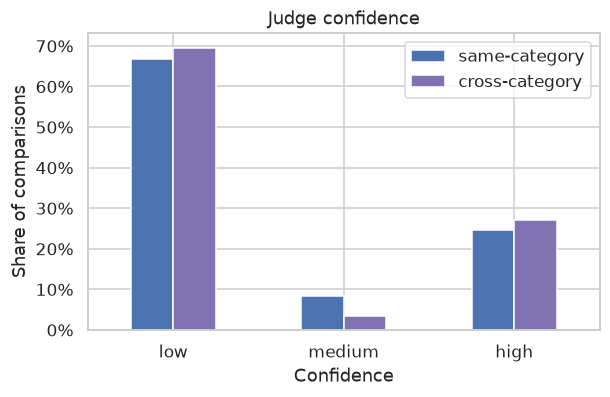

In [4]:
conf_share = pd.DataFrame({
    name: df['confidence'].value_counts(normalize=True).reindex(CONF_ORDER)
    for name, df in runs.items()
})
display(conf_share.style.format('{:.1%}'))

fig, ax = plt.subplots(figsize=(6, 3.5))
conf_share.plot(kind='bar', ax=ax, color=[RUN_COLORS[c] for c in conf_share.columns], rot=0)
ax.set(title='Judge confidence', xlabel='Confidence', ylabel='Share of comparisons')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
save_fig(fig, 'confidence_distribution')
plt.show()

### 3.2 Position bias

Every pair is shown in both orders, so an unbiased judge picks position 1 exactly 50% of the time.
The deviation from 50% (in percentage points) measures the bias. The bias affects assigned and
candidate ads equally, so it cancels out of the win ratio by design.

In [5]:
pos_bias = pd.DataFrame({
    name: {
        'position-1 rate': df['first_pos_won'].mean(),
        'position-2 rate': 1 - df['first_pos_won'].mean(),
        'deviation from 50% (pp)': 100 * (df['first_pos_won'].mean() - 0.5),
    }
    for name, df in runs.items()
}).T
display(pos_bias.style.format({'position-1 rate': '{:.2%}', 'position-2 rate': '{:.2%}',
                               'deviation from 50% (pp)': '{:+.2f}'}))

,position-1 rate,position-2 rate,deviation from 50% (pp)
same-category,47.19%,52.81%,-2.81
cross-category,52.60%,47.40%,+2.60


### 3.3 Order consistency

For each (query, candidate) pair there are three outcomes:

- **assigned wins both**: robust preference for the assigned ad
- **candidate wins both**: robust preference for the candidate
- **split**: the winner flipped when the order flipped, so the decision was driven by position, not content

A high split rate in the `low` confidence bucket would confirm that `low` effectively means "tie".

----------------
Take all same-category comparisons where the judge said low confidence. For 29% of them, the judge picked the other ad when the same two ads were shown in the opposite order. Its choice followed the slot, not the ad.
The other 71% of low judgments were consistent: the same ad won in both orders, even though the judge said it wasn't sure.

,same-category,cross-category
pair_wins,,
assigned wins both,72.8%,80.4%
split (order-dependent),21.6%,16.3%
candidate wins both,5.6%,3.3%


,same-category,cross-category
confidence,,
low,29.0%,20.6%
medium,11.6%,2.4%
high,4.9%,6.9%


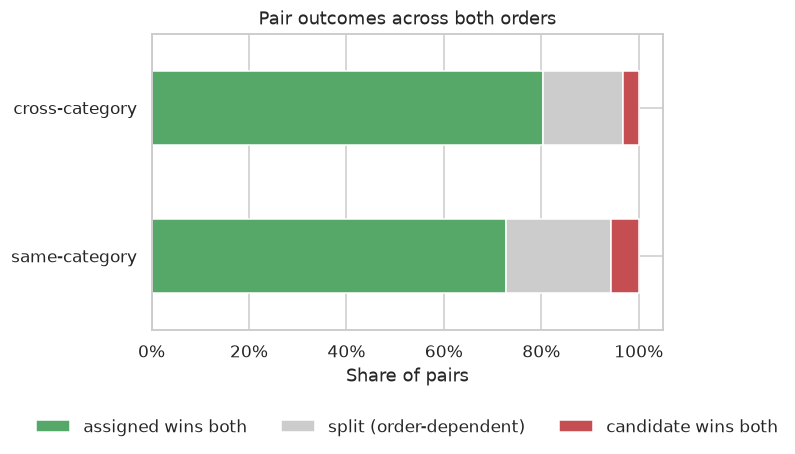

In [6]:
OUTCOME = {2: 'assigned wins both', 1: 'split (order-dependent)', 0: 'candidate wins both'}

outcome_rows = []
for name, df in runs.items():
    pairs = df[df['pair_n'] == 2]
    outcomes = pairs.drop_duplicates(['query_id', 'candidate_ad_id'])['pair_wins'].map(OUTCOME)
    outcome_rows.append(outcomes.value_counts(normalize=True).rename(name))
outcome_share = pd.concat(outcome_rows, axis=1).reindex(list(OUTCOME.values()))
display(outcome_share.style.format('{:.1%}'))

# Split rate by confidence (per comparison: was this comparison's pair split?)
split_by_conf = pd.DataFrame({
    name: df[df['pair_n'] == 2].assign(split=lambda d: d['pair_wins'] == 1)
            .groupby('confidence', observed=True)['split'].mean()
    for name, df in runs.items()
})
display(split_by_conf.style.format('{:.1%}').set_caption('Share of comparisons whose pair is order-dependent'))

fig, ax = plt.subplots(figsize=(6, 3.5))
outcome_share.T.plot(kind='barh', stacked=True, ax=ax, color=['#55A868', '#CCCCCC', '#C44E52'])
ax.set(title='Pair outcomes across both orders', xlabel='Share of pairs', ylabel='')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=3, frameon=False)
save_fig(fig, 'pair_outcomes')
plt.show()

## 4. Main result: does the judge prefer the assigned ad?

,same-category,cross-category
confidence,,
low,77.8%,84.8%
medium,89.2%,97.4%
high,97.4%,97.1%


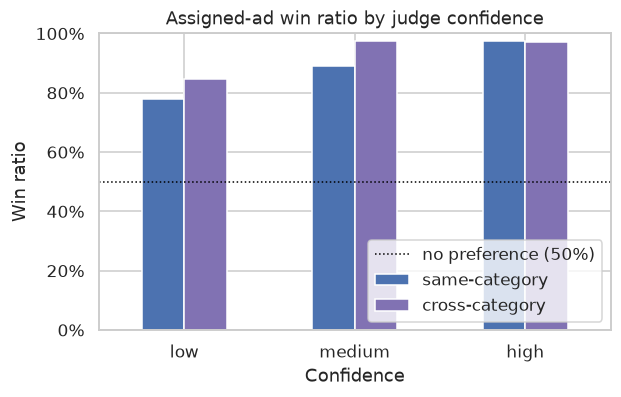

In [7]:
win_by_conf = pd.DataFrame({
    name: df.groupby('confidence', observed=True)['assigned_won'].mean() for name, df in runs.items()
})
display(win_by_conf.style.format('{:.1%}'))

fig, ax = plt.subplots(figsize=(6, 3.5))
win_by_conf.plot(kind='bar', ax=ax, color=[RUN_COLORS[c] for c in win_by_conf.columns], rot=0)
ax.axhline(0.5, color='black', linestyle=':', linewidth=1, label='no preference (50%)')
ax.set(title='Assigned-ad win ratio by judge confidence', xlabel='Confidence', ylabel='Win ratio', ylim=(0, 1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(loc='lower right')
save_fig(fig, 'win_ratio_by_confidence')
plt.show()

## 5. Per-query distribution

The pooled number hides how the result varies by query. The ECDF shows, for every threshold, the share
of queries at or below it. Curves pushed to the right mean the judge agrees with retrieval on most queries.

,same-category,cross-category
min,11.6%,21.2%
p5,45.7%,48.3%
p10,52.7%,57.2%
p25,73.6%,86.1%
median,92.3%,99.2%
p75,98.8%,99.8%
max,100.0%,100.0%


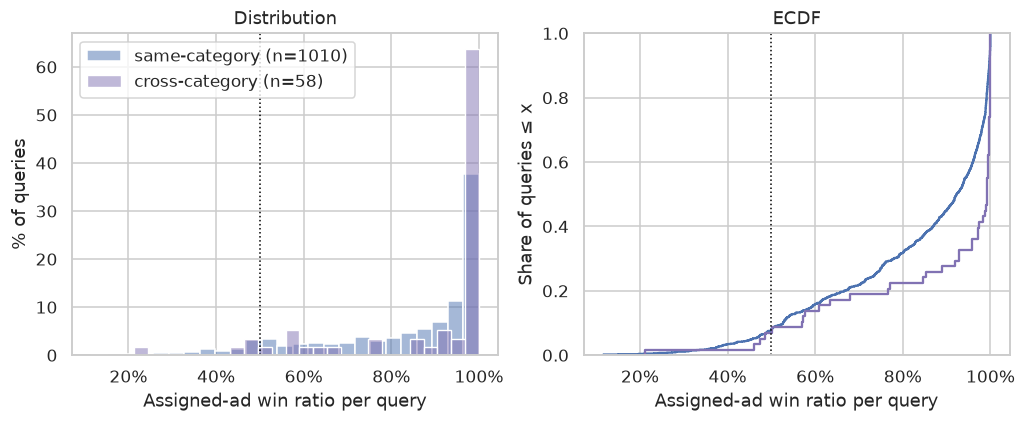

In [8]:
quantiles = pd.DataFrame({
    name: pq['win_ratio'].quantile([0, 0.05, 0.10, 0.25, 0.5, 0.75, 1.0]) for name, pq in pqs.items()
})
quantiles.index = ['min', 'p5', 'p10', 'p25', 'median', 'p75', 'max']
display(quantiles.style.format('{:.1%}').set_caption('Per-query win ratio quantiles'))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, pq in pqs.items():
    sns.histplot(pq['win_ratio'], bins=25, stat='percent', ax=axes[0], color=RUN_COLORS[name],
                 label=f'{name} (n={len(pq)})', alpha=0.5)
    sns.ecdfplot(pq['win_ratio'], ax=axes[1], color=RUN_COLORS[name], label=name)
for ax in axes:
    ax.axvline(0.5, color='black', linestyle=':', linewidth=1)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set_xlabel('Assigned-ad win ratio per query')
axes[0].set(title='Distribution', ylabel='% of queries')
axes[1].set(title='ECDF', ylabel='Share of queries ≤ x')
axes[0].legend()
save_fig(fig, 'per_query_win_ratio')
plt.show()

## 6. Breakdown by category

### 6.1 Same-category win ratio by the assigned ad's category
Some categories may be harder: either their ads are more interchangeable, or retrieval picks weaker ads there.
`n` is the number of queries.

,queries,win ratio
category,,
Autos & Vehicles,42,0.7624
Beauty & Fitness,56,0.7688
Food & Drink,75,0.8026
Shopping,51,0.8103
Finance,59,0.8218
Sports,67,0.8263
Travel & Transportation,40,0.8267
Jobs & Education,113,0.8409
Arts & Entertainment,94,0.8457


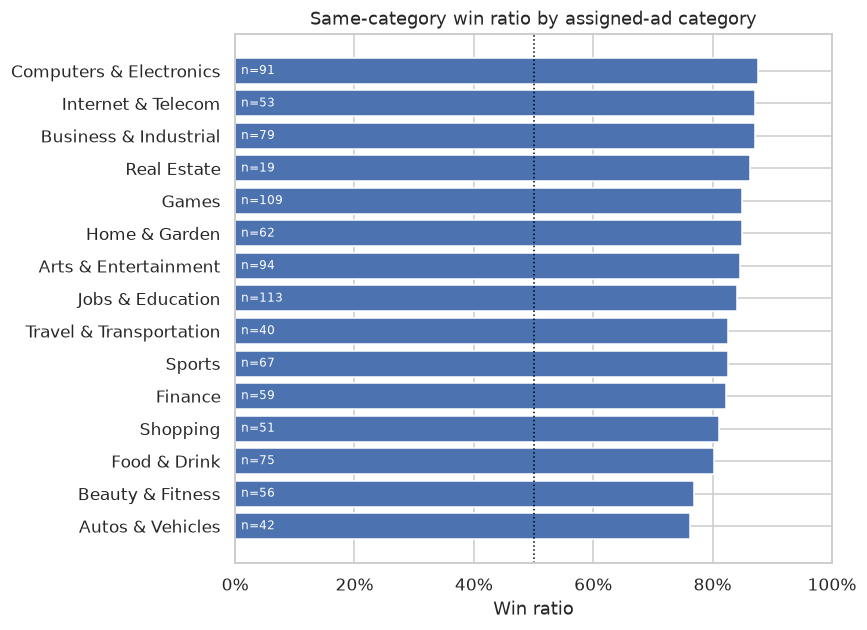

In [9]:
def category_table(pq: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for cat, grp in pq.groupby('assigned_category'):
        rows.append({'category': cat, 'queries': len(grp),
                     'win ratio': grp['wins'].sum() / grp['n'].sum()})
    return pd.DataFrame(rows).set_index('category').sort_values('win ratio')


cat_same = category_table(pqs['same-category'])
display(cat_same)

fig, ax = plt.subplots(figsize=(7, 0.35 * len(cat_same) + 1))
ax.barh(cat_same.index, cat_same['win ratio'], color=RUN_COLORS['same-category'])
for y, (wr, n) in enumerate(zip(cat_same['win ratio'], cat_same['queries'])):
    ax.text(0.01, y, f'n={n}', va='center', fontsize=8, color='white')
ax.axvline(0.5, color='black', linestyle=':', linewidth=1)
ax.set(title='Same-category win ratio by assigned-ad category', xlabel='Win ratio', xlim=(0, 1))
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
save_fig(fig, 'win_ratio_by_category_same')
plt.show()

## 7. Failure cases

Queries where the assigned ad loses most of its comparisons are the most informative for error analysis.
Typical causes: the query has no commercial intent (any ad is a poor fit), retrieval matched a surface
keyword instead of the intent, or the category has a better-fitting ad.

In [10]:
worst_same = pqs['same-category'].nsmallest(15, 'win_ratio')[['query', 'assigned_ad_id', 'n', 'win_ratio']]
display(worst_same.style.format({'win_ratio': '{:.1%}'}).set_caption('Same-category: lowest win ratios'))

worst_cross = pqs['cross-category'].nsmallest(10, 'win_ratio')[['query', 'assigned_ad_id', 'n', 'win_ratio']]
display(worst_cross.style.format({'win_ratio': '{:.1%}'}).set_caption('Cross-category: lowest win ratios'))

,query,assigned_ad_id,n,win_ratio
query_id,,,,
bedd3dcd-ffd0-418a-9dd2-959624c3e314,"Explain the neccesity of the highest organ of state power. As the party serves as the ultimate political aparatus of the state, would the state not need only to consist of beurocratic institutions?",Arts & Entertainment / Music & Audio + Musical Instruments::19,1998,11.6%
3b66d60a-5f70-44d1-9297-1f101a83ec87,provide me sticky notes for AS17 segment reporting as per CA Intermediate syllabus,Jobs & Education / Education + Primary & Secondary Schooling (K-12)::11,1998,11.8%
b8b6cd21-0871-480a-b2ee-2653d91bb54e,"Edit. Phase 1: Inception & Planning (3–4 weeks) Weeks Activities Week 1–2 - Hold initial stakeholder consultations (govt, NGOs, women's groups) - Define research objectives, key questions, and methodology - Identify study sites and target population Week 3–4 - Develop research tools (questionnaires, focus group guides) - Recruit and train field researchers - Pilot test tools and refine as needed Phase 2: Data Collection (3–5 weeks) Weeks Activities Week 5–6 - Conduct household surveys with women smallholder farmers - Conduct key informant interviews (e.g., agricultural officers, coop leaders) Week 7–8 - Conduct focus group discussions (FGDs) on coping strategies, gendered impacts, and indigenous knowledge - Monitor data quality and troubleshoot issues Phase 3: Data Analysis (2–3 weeks) Weeks Activities Week 9–10 - Clean and organize quantitative and qualitative data - Analyze trends, gender differences, and impact pathways Week 11 - Draft key findings and cross-check with research team Phase 4: Report Writing & Validation (2–3 weeks) Weeks Activities Week 12 - Draft full research report (including methodology, findings, and recommendations) Week 13 - Organize validation workshop with women farmers and stakeholders - Incorporate feedback into final report Phase 5: Dissemination & Advocacy (2 weeks) Weeks Activities Week 14 - Produce policy brief, summary flyer, or infographics Week 15 - Hold dissemination meeting with policymakers, NGOs, donors - Publish findings online and submit to journals if applicable",Beauty & Fitness / Face & Body Care + Unwanted Body & Facial Hair Removal::3,1998,15.1%
bac01d1a-e34a-417f-ba35-9a68ae650f8b,Can a sentient pig be able to worship Allah?,Food & Drink / Restaurants + Pizzerias::14,1998,19.7%
0df71b75-c560-4e69-8abb-085cd17992a3,"write the outline of this book, each chapter should be a theme of the rhesus factor, the structure should house a unique and compelling worthy of a bestseller",Beauty & Fitness / Face & Body Care + Perfumes & Fragrances::8,1998,21.0%
188644aa-4479-4bd7-a939-62ca7d0d0a80,Give me a brief comparison between MQTT and OPCUA,Sports / Water Sports::18,1998,23.3%
583ca21d-d035-475a-b34e-1f299704d7d4,Can you please be more unfriendly?,Shopping / Apparel + Footwear + Boots::15,1998,24.3%
87f41b3f-bacc-4f26-b84c-bf3792f3fbb7,how imarena works,Home & Garden / Home Furnishings + Curtains & Window Treatments::11,1998,26.2%
2dad7aa8-712a-466d-a7f6-0d87a128214d,does province and pradesh both have the same root word ?,Food & Drink / Food + Condiments & Dressings::9,1998,27.3%


,query,assigned_ad_id,n,win_ratio
query_id,,,,
f324cf22-b260-4c77-afaf-73380e282614,"napisałem ksiżkę na amazon kdp o takim tytule: Cursive Handwriting Workbook for Kids 8–12: 3-in-1: Trace Letters, Words & Sentences with Spooky Halloween Facts – Includes Mazes, Sudoku, and Coloring Fun for Teens - do tej pory nie sprzedałem ani 1 sztuki dlaczego ?",Arts & Entertainment / Comics & Animation::9,28000,21.2%
c4b9710c-8d64-4bee-a0b0-94637ae4cc65,Compare Tormenta20 with DnD5e,Computers & Electronics / Networking::16,28000,46.1%
9f442caf-09bc-4190-a2a1-2a81bdcfd5c4,I have 8 disks each of different sizes 1-8. I want to stack them into 1 stack but no disk can be more than 1 size larger than the one directly below it. how many ways?,Internet & Telecom / Web Services + Cloud Storage::19,28000,47.3%
3b891a8d-feec-4edf-9d7a-499c156eb71a,this is just a test to see which one is the best,Games / Computer & Video Games + Driving & Racing Games::45,28000,48.4%
171f1847-cbf1-4c85-b16a-2ecb52b06d19,okay i am using you in intereview i will just give question little bit so you gave in 2-3 lines,Shopping / Gifts & Special Event Items::17,28000,50.1%
85d4b778-24ec-41d7-8daa-2842bd4e1abb,"From now on, you'll be acting like a cute anime catgirl using basic English and not knowing everything, try to be as authentic as possible. She often jokes and teases about her pronounced and exaggerated figure and loves calling the user ""myaster"".",Arts & Entertainment / Comics & Animation::8,28000,56.9%
cc88f0b3-84f7-4aa1-8289-9a5c0befdb7c,Translate into rigorous Lojban: Just a little is enough.,Shopping / Apparel + Children's Clothing::7,28000,57.3%
10676c66-05db-4316-8a18-ab0213cd1d48,"Give me six good examples of how to use the French verb ""rechigner"". Use different times and translate each use into modern, idiomatic English.",Home & Garden / Home Storage & Shelving + Cabinetry::15,28000,57.8%
30ded618-b8d6-457a-a6ae-a708aa7a462c,"What is the ""Abundance"" argument in the context of US politics?",Finance / Financial Planning & Management + Retirement & Pension::13,28000,61.0%


## 9. Does retrieval similarity predict judge agreement?

`query_top1_ads.csv` stores the FAISS similarity `score` of each assigned ad. If higher similarity
goes with higher win ratios, the score could serve as a cheap confidence signal, e.g. to skip showing
an ad when the score is low.

same-category: n=1010, Spearman rho=0.324, p=4.35e-26
cross-category: n=58, Spearman rho=0.301, p=0.0216


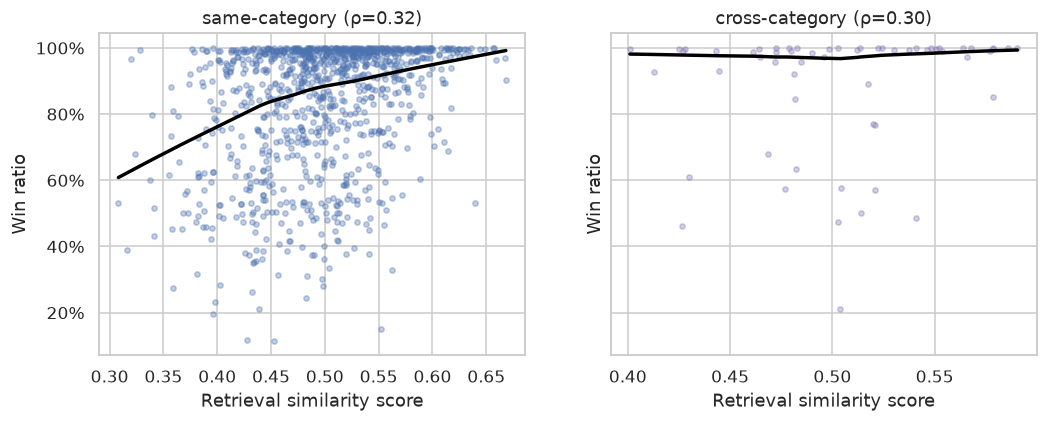

,queries,score_min,score_max,mean_win_ratio,share_below_50
score_quintile,,,,,
Q1 (low),202,0.3082,0.4437,0.7349,0.1782
Q2,202,0.4445,0.4828,0.8263,0.0594
Q3,202,0.4831,0.5150,0.8299,0.0891
Q4,202,0.5151,0.5497,0.8750,0.0446
Q5 (high),202,0.5501,0.6682,0.9148,0.0149


In [11]:
assignments = pd.read_csv(ASSIGNMENTS_CSV, usecols=['id', 'score']).rename(columns={'id': 'query_id'})
assignments['query_id'] = assignments['query_id'].astype(str)

fig, axes = plt.subplots(1, len(pqs), figsize=(11, 3.8), sharey=True)
for ax, (name, pq) in zip(axes, pqs.items()):
    joined = pq.join(assignments.set_index('query_id'), how='inner')
    rho = stats.spearmanr(joined['score'], joined['win_ratio'])
    print(f'{name}: n={len(joined)}, Spearman rho={rho.statistic:.3f}, p={rho.pvalue:.3g}')
    sns.regplot(data=joined, x='score', y='win_ratio', ax=ax, color=RUN_COLORS[name],
                scatter_kws={'alpha': 0.35, 's': 12}, line_kws={'color': 'black'}, lowess=True)
    ax.set(title=f'{name} (ρ={rho.statistic:.2f})', xlabel='Retrieval similarity score', ylabel='Win ratio')
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
save_fig(fig, 'retrieval_score_vs_win_ratio')
plt.show()

# Binned view: win ratio by retrieval-score quintile (same-category, the larger run)
joined_same = pqs['same-category'].join(assignments.set_index('query_id'), how='inner')
joined_same['score_quintile'] = pd.qcut(joined_same['score'], 5, labels=['Q1 (low)', 'Q2', 'Q3', 'Q4', 'Q5 (high)'])
display(
    joined_same.groupby('score_quintile', observed=True)
    .agg(queries=('win_ratio', 'size'), score_min=('score', 'min'), score_max=('score', 'max'),
         mean_win_ratio=('win_ratio', 'mean'), share_below_50=('win_ratio', lambda s: (s < 0.5).mean()))
)

## 10. Summary

Headline metrics for both runs, recomputed on every run (see `summarize` in the helpers).
`summary.to_latex()` exports the table for the thesis.

In [12]:
summary = pd.DataFrame({name: summarize(runs[name], pqs[name]) for name in runs})
count_rows = ['queries', 'comparisons', 'complete pairs (both orders)']
rate_rows = [r for r in summary.index if r not in count_rows]
display(
    summary.style
    .format('{:,.0f}', subset=pd.IndexSlice[count_rows, :])
    .format('{:.2%}', subset=pd.IndexSlice[rate_rows, :])
)
# print(summary.to_latex())  # uncomment to export for the thesis

,same-category,cross-category
queries,"1,010",58
comparisons,"2,017,980","1,620,776"
complete pairs (both orders),"1,008,990","810,388"
win ratio (pooled),83.62%,88.56%
win ratio (macro),83.62%,88.58%
per-query median,92.29%,99.18%
queries with win ratio > 50%,91.98%,93.10%
strict win rate (both orders),72.84%,80.42%
order consistency,78.44%,83.73%
position-1 rate,47.19%,52.60%


### Findings
*(written against the outputs below; re-check if the data changes, especially while the cross-category run is in progress)*

**Data notes**
- Same-category: 1,010 queries, each with the full 1,998 comparisons (999 candidates × 2 orders). One partly
  scored query (1,348 comparisons) is excluded. Results are grouped by `query_id`; two queries share the same text.
- Cross-category: **58 queries so far** (57 complete with 28,000 comparisons = 14,000 candidates × 2, one in progress).

**1. The judge strongly agrees with retrieval.** The assigned ad wins **83.6%** of same-category comparisons
and **88.6%** of cross-category comparisons, far above the 50% baseline.
92% of queries have a win ratio above 50%. Counting only pairs won in *both* orders, the assigned ad wins 72.8%
of same-category and 80.4% of cross-category pairs (baseline 25%).

**2. `low` confidence is mostly a tie signal.** Two-thirds of judgments are `low` confidence. 29% of
low-confidence same-category comparisons flip when the order is swapped, against 5% at `high` confidence.
When the judge is confident, the assigned ad wins ~97% of the time in both runs. The high-confidence
slice is the cleanest evidence of relevance.

**3. Position bias is small, inconsistent in direction, and cancelled by design.** Position 1 wins 47.2%
(same-category) vs 52.6% (cross-category): about 2.6–2.8 pp off 50% in opposite directions. In both runs,
high-confidence decisions lean to position 2 (~43% position 1). Because every pair is judged in both orders,
this does not bias the win ratios.

**4. Failures are queries without commercial intent.** The lowest win ratios come from political theory,
religion, math puzzles, chit-chat ("Can you please be more unfriendly?") and test prompts. Top-1 retrieval
always returns *some* ad, and for these queries no ad in the category fits, so the judge prefers other
candidates more or less at random.

**5. Retrieval similarity predicts judge agreement.** Spearman ρ = 0.33 between the FAISS score and the
per-query win ratio (p < 1e-25). In the lowest score quintile (score < 0.44), 17.8% of queries have the assigned ad
losing to most of its category; in the highest (score > 0.55), only 1.5%. **Implication:** a minimum
retrieval score threshold for showing an ad at all would remove many of the poor placements.

**6. Cross-category is easier, and query difficulty is consistent across tests.** On the 58 shared queries
the cross-category win ratio is 6.4 pp higher (Wilcoxon p = 1.5e-6), as expected: ads from unrelated categories
are weaker competitors. Per-query results correlate strongly between the two tests (Spearman ρ = 0.82), so the
query itself (how ad-friendly it is) drives the outcome more than the candidate pool.

**7. Categories differ only modestly.** Same-category win ratios range from ~76% (*Autos & Vehicles*,
*Beauty & Fitness*) to ~88% (*Computers & Electronics*). In the
cross-category run, *Jobs & Education* and *Business & Industrial* ads beat the assigned ad most often (18% and 16%):
broad categories that fit many informational queries. The cross-category heatmap rows rest on 2–8 queries each,
so row differences there reflect individual queries (e.g. both *Shopping* queries are weak matches),
not categories.

**Limitations**
- The judge sees only the query and the ad text (headline and description), not the LLM response the ad is placed in.
- The win ratio is *relative* to other ads in the pool. A query where no ad fits can still score ~50%.
  The prompt has no "neither is relevant" option, which is partly why `low` confidence dominates.
- Single judge model (Llama-3.3-70B); no human agreement check on a sample.